# Reproduce: grain vs silage corn at BARC

This notebook rebuilds every input and result in `research/grain_vs_silage/` from public data, one step at a
time. It runs the same scripts as `reproduce.py`, so the two always agree. Methods and the meaning of every
number: [`METHODOLOGY.md`](METHODOLOGY.md).

| Step | What happens | Time |
|---|---|---|
| 0 | Settings, package check | seconds |
| 1 | Download the BARC farm records (Zenodo, md5-checked) and build the 2017-2020 training labels | seconds |
| 2 | Pull Sentinel-2, Landsat and Daymet for 2021-2023 and 2017-2020 (skipped if already present) | 10-30 min per pull |
| 3 | Features, every validation split, figures | about a minute |
| 4 | AlphaEarth embeddings and the model comparison (logistic, random forest, XGBoost) | a few minutes the first time |
| 5 | Check the headline numbers against the expected ones | seconds |

Everything is written to `data/` (git-ignored, at the repo root) and `results/` (this folder). Steps whose
outputs already exist are skipped, so **Run All** is safe to repeat. No accounts or API keys are needed.

The saved outputs below are from a run on Windows 11, Python 3.12.10, with the input files already present.

In [1]:
# ---- Settings -------------------------------------------------------------------------------------------
INSTALL = False     # True: pip-install requirements.txt into THIS kernel (avoid on a shared team server)
WORKERS = 8         # parallel scene reads; use 4 if many scene-days fail (Planetary Computer throttles)
FORCE_PULL = False  # True: re-pull the imagery even if data/series_*.parquet already exist

import importlib, json, platform, subprocess, sys, time
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "preprocessing" / "loader.py").exists())
HERE = ROOT / "research" / "grain_vs_silage"
DATA, RESULTS = ROOT / "data", HERE / "results"
PY = sys.executable
print("repo root:", ROOT)
print("python   :", PY, platform.python_version(), "|", platform.platform())


def run(*args, show="all"):
    """Run a script with this kernel's Python from the repo root. show='all' streams every line,
    an int shows only the last N lines, 0 shows nothing. Returns the output lines."""
    cmd = [PY, *map(str, args)]
    print(">>", " ".join(str(a) for a in args), flush=True)
    t = time.time()
    p = subprocess.Popen(cmd, cwd=ROOT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
                         encoding="utf-8", errors="replace")
    lines = []
    for line in p.stdout:
        lines.append(line.rstrip("\n"))
        if show == "all":
            print(line, end="", flush=True)
    p.wait()
    if isinstance(show, int) and show > 0:
        print("\n".join(lines[-show:]))
    print(f"[exit {p.returncode}, {time.time() - t:.0f} s]")
    if p.returncode:
        raise RuntimeError("step failed; see the output above")
    return lines

repo root: <repo>
python   : <repo>\.venv\Scripts\python.exe 3.12.10 | Windows-11-10.0.26200-SP0


In [2]:
if INSTALL:
    subprocess.run([PY, "-m", "pip", "install", "-r", str(HERE / "requirements.txt")], check=True)

need = ["numpy", "pandas", "pyarrow", "geopandas", "shapely", "rasterio", "odc.stac", "odc.geo", "pystac_client",
        "planetary_computer", "sklearn", "scipy", "xgboost", "matplotlib"]
missing = []
for m in need:
    try:
        print(f"{m:20s} {getattr(importlib.import_module(m), '__version__', 'installed')}")
    except ImportError:
        missing.append(m)
        print(f"{m:20s} MISSING")
if missing:
    raise SystemExit("Install the requirements first: set INSTALL = True above, or run "
                     "pip install -r research/grain_vs_silage/requirements.txt")

numpy                2.5.4


pandas               3.1.1
pyarrow              26.0.1


geopandas            1.2.0
shapely              2.2.0
rasterio             1.5.2


odc.stac             0.5.3
odc.geo              0.5.4
pystac_client        0.9.1
planetary_computer   1.0.0


sklearn              1.9.1
scipy                1.18.1
xgboost              3.4.1
matplotlib           3.11.2


## Step 1: training labels from the BARC farm records

Kraatz (2023), Zenodo record [8087301](https://doi.org/10.5281/zenodo.8087301), CC-BY 4.0. `kraatz_fields.py`
turns the planting and harvest tables into Grain/Silage labels for 2017-2020 and matches each field to a
polygon. Field-years with no polygon are dropped rather than guessed.

In [3]:
import urllib.request
sys.path.insert(0, str(HERE))
import reproduce as rp  # reuse the file list, md5 sums and URLs from reproduce.py

kdir = DATA / "kraatz_zenodo_8087301"
kdir.mkdir(parents=True, exist_ok=True)
for name, want in rp.KRAATZ_FILES.items():
    p = kdir / name
    if not p.exists() or rp.md5(p) != want:
        print("downloading", name)
        urllib.request.urlretrieve(rp.ZENODO.format(name=name), p)
    assert rp.md5(p) == want, f"md5 mismatch for {p}"
    print(f"ok  {name}  ({p.stat().st_size / 1e6:.1f} MB, md5 {want})")

run(HERE / "kraatz_fields.py", "--kraatz-dir", kdir, "--gpkg", rp.EVAL_GPKG, "--out", DATA);

ok  farm_database_annual_planting_harvesting_after_some_screening..zip  (0.0 MB, md5 65590c4f15b2179599bf676172ab36ba)
ok  barc_field_outlines_for_study.zip  (0.1 MB, md5 35fae5dc89622d483b11e4a370f26d9c)
>> <repo>\research\grain_vs_silage\kraatz_fields.py --kraatz-dir <repo>\data\kraatz_zenodo_8087301 --gpkg <repo>\04_Evaluation\BARC_Corn.2021-2023.gpkg --out <repo>\data


2021 corn records (harvest-date check only): 42, with harvest date: 38


corn field-years in records: 135; ambiguous (both classes) dropped: 0; planting vs harvest class differ (harvest kept): 1


no polygon, dropped: 52 field-years (1-30_1-30, APU_4, CentralFarm_1-14A, CentralFarm_1-14E, CentralFarm_1-2A, CentralFarm_1-2C, CentralFarm_1-7, CentralFarm_1-7A, CentralFarm_1-7C, CentralFarm_1-7D, CentralFarm_1-7E, CentralFarm_1-7F...)


label                 Grain  Silage  All


year label_source                       


... (5 outputs left out)

     planting record      8       1    9


All                      64      19   83


polygons: 54 (46 from the eval gpkg, 8 Kraatz outlines)


[exit 0, 1 s]


## Step 2: satellite and weather series

`preprocessing/loader.py` reads Sentinel-2 L2A and Landsat 8/9 from Microsoft Planetary Computer (1 Mar to 31 Dec
each year), masks clouds per pixel, shrinks each field 10 m inward, and writes one median value per field, date
and sensor, plus Daymet daily weather. Planetary Computer throttles bursts, so failed scene-days are retried
once automatically. Each pull writes a provenance JSON (every query, rule and failure) next to its parquet.

In [4]:
pulls = [("barc", ["--gpkg", rp.EVAL_GPKG, "--years", 2021, 2022, 2023]),
         ("kraatz_2017_2020", ["--fields", DATA / "fields_kraatz_2017_2020.gpkg", "--years", 2017, 2018, 2019, 2020])]
for tag, src in pulls:
    common = ["preprocessing/loader.py", *src, "--tag", tag, "--cell-m", 50000, "--workers", WORKERS]
    if FORCE_PULL or not (DATA / f"series_{tag}.parquet").exists():
        run(*common, "--weather", show=20)
        prov = json.loads((DATA / f"series_{tag}.provenance.json").read_text())
        if prov["failures"]:
            print(len(prov["failures"]), "scene-days failed; retrying them once")
            run(*common, "--retry-failed", show=5)
    else:
        print(f"data/series_{tag}.parquet exists; pull skipped (set FORCE_PULL = True to redo it)")

data/series_barc.parquet exists; pull skipped (set FORCE_PULL = True to redo it)
data/series_kraatz_2017_2020.parquet exists; pull skipped (set FORCE_PULL = True to redo it)


In [5]:
import pandas as pd
for tag in ("barc", "kraatz_2017_2020"):
    s = pd.read_parquet(DATA / f"series_{tag}.parquet")
    prov = json.loads((DATA / f"series_{tag}.provenance.json").read_text())
    years = sorted(int(y) for y in s.year.unique())
    print(f"{tag}: {len(s):,} rows | {s.field_id.nunique()} fields | years {years} | "
          f"usable readings {int(s.usable.sum()):,}")
    if "sources" in prov:  # a file assembled from earlier loader runs: report their failures
        print("   note:", prov["note"])
        for src in prov["sources"]:
            if not (DATA / src).exists():
                print(f"   {src}: not on this machine")
                continue
            sp = json.loads((DATA / src).read_text())
            print(f"   {src}: {len(sp.get('failures', []))} of {sp.get('scene_days')} scene-day reads failed "
                  f"(not retried)")
    else:
        print(f"   failed scene-days left: {len(prov.get('failures', []))}")

barc: 25,700 rows | 83 fields | years [2021, 2022, 2023] | usable readings 14,744
   note: local assembly, not a single loader run: Sentinel-2 rows from series_barc_v011_4cells (loader 0.1.1, after the duplicate-scene fix) + Landsat rows from series_barc_landsat_v012 (loader 0.1.2, grid fix). Same content a 0.1.2+ loader run produces; see those files' provenance JSONs.
   series_barc_v011_4cells.provenance.json: 4 of 1136 scene-day reads failed (not retried)
   series_barc_landsat_v012.provenance.json: 1 of 82 scene-day reads failed (not retried)
kraatz_2017_2020: 20,736 rows | 54 fields | years [2017, 2018, 2019, 2020] | usable readings 9,463
   failed scene-days left: 0


## Step 3: features, validation and figures

`grain_silage.py` puts Landsat on the Sentinel-2 scale, drops isolated cloud dips, builds 38 features per
field-year, and runs every validation split. The full output is `results/report.md`; below are the data-quality
lines and the figures.

In [6]:
lines = run(HERE / "grain_silage.py", show=0)
for l in lines:
    if l.startswith("merged readings"):
        print(l)
report = (RESULTS / "report.md").read_text(encoding="utf-8").splitlines()
for l in report:
    if l.startswith(("Labeled field-years", "2017-2020 labeled", "Min usable readings")):
        print(l)
run(HERE / "make_figures.py", show=1);

>> <repo>\research\grain_vs_silage\grain_silage.py


[exit 0, 5 s]
merged readings: 13684; isolated dips removed: 114
merged readings: 8949; isolated dips removed: 138
Labeled field-years: 44 (Grain 32, Silage 12); blank labels are unlabeled and excluded.
Min usable readings Aug-Nov per labeled field-year: 13
2017-2020 labeled field-years: 83 (Grain 64, Silage 19)
Min usable readings Aug-Nov: 11; field-years with fewer than 8: 0
>> <repo>\research\grain_vs_silage\make_figures.py


wrote <repo>\research\grain_vs_silage\results\fig_ndvi_trajectories.png and fig_key_features.png
[exit 0, 3 s]


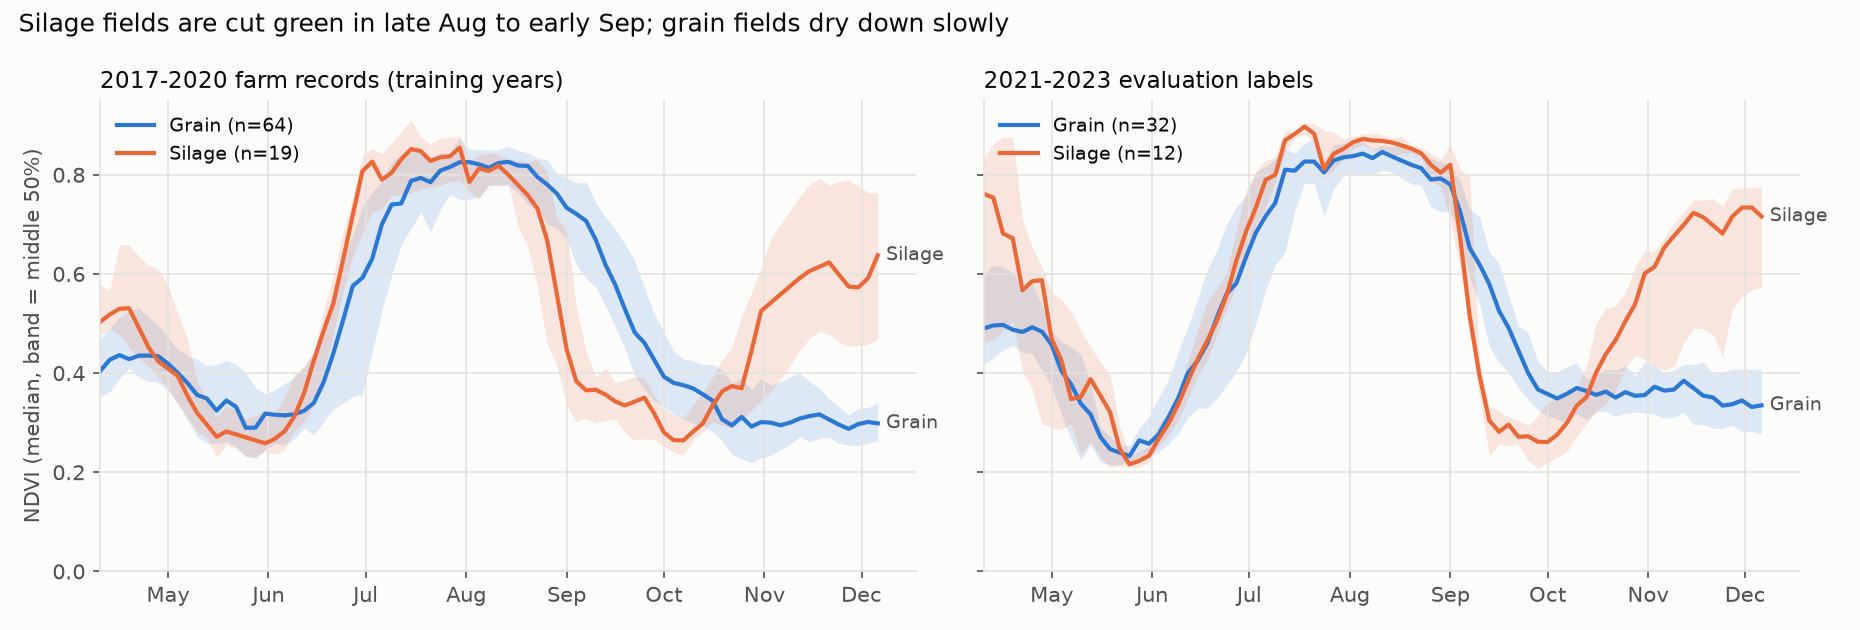

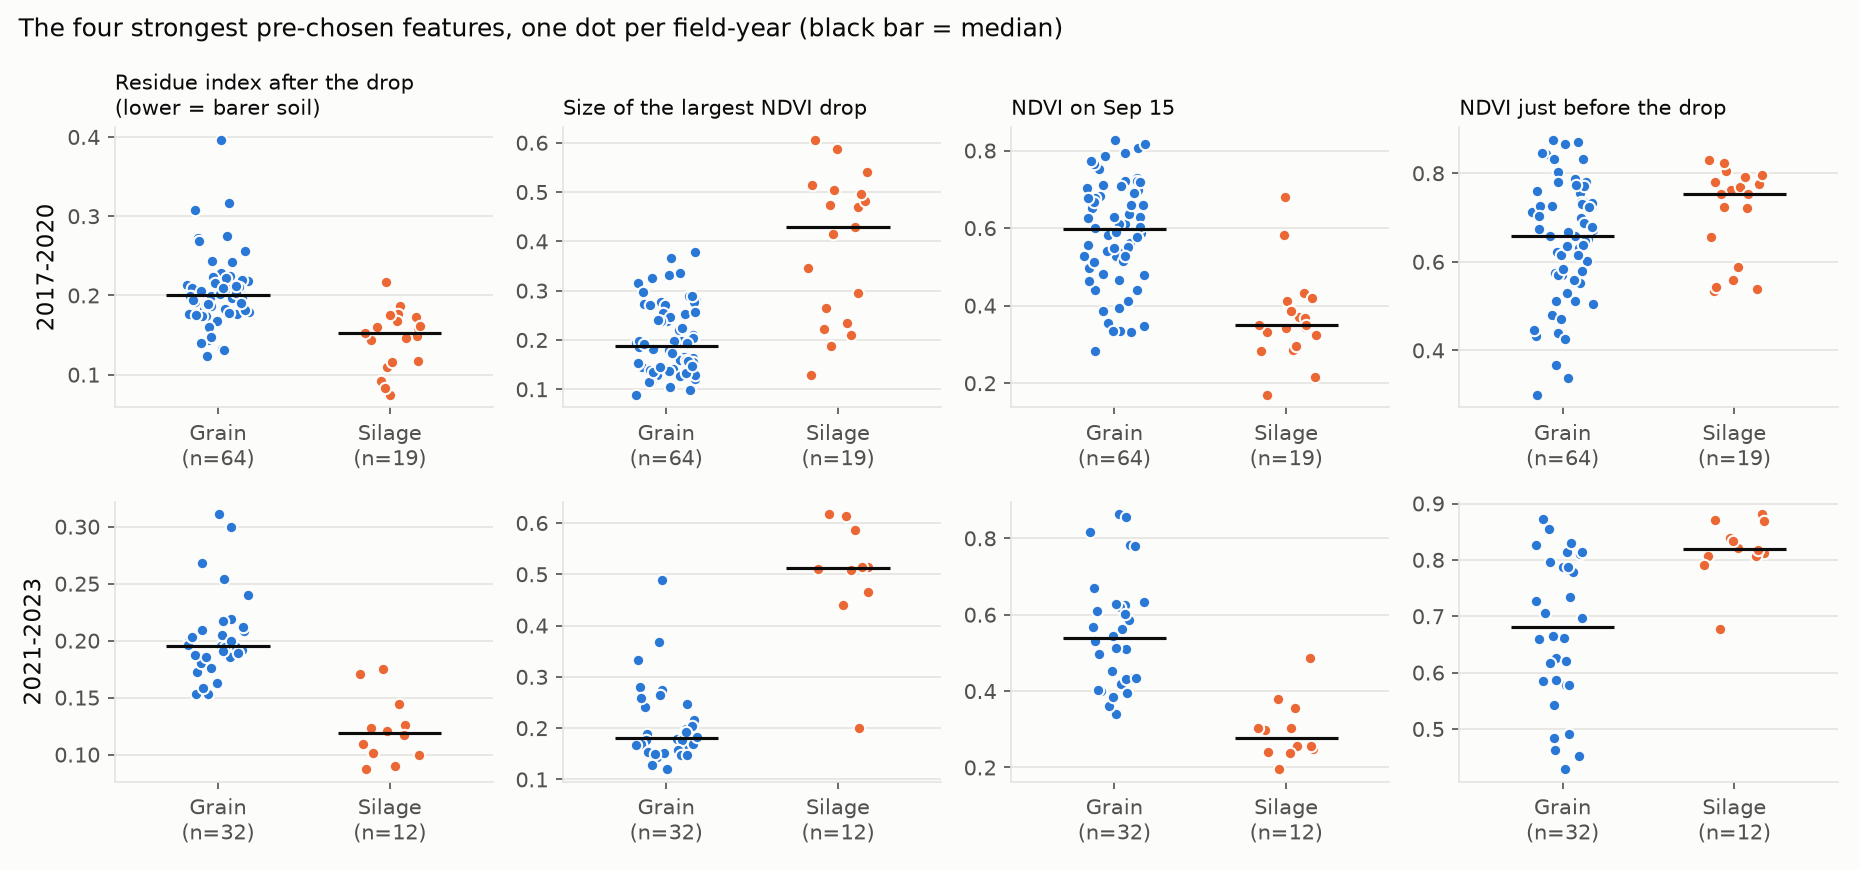

In [7]:
from IPython.display import Image, Markdown, display
display(Image(filename=str(RESULTS / "fig_ndvi_trajectories.png"), width=900))
display(Image(filename=str(RESULTS / "fig_key_features.png"), width=900))

## Step 4: AlphaEarth embeddings and the model comparison

`aef_embeddings.py` reads Google DeepMind's AlphaEarth annual embeddings (64 numbers per 10 m pixel, CC-BY 4.0,
from Source Cooperative) and averages them per field-year. `model_comparison.py` scores logistic regression,
random forest and XGBoost on four feature sets over six splits. It stops with an error unless the original
numbers reproduce, and it chooses a model using 2017-2020 only.

In [8]:
run(HERE / "aef_embeddings.py", show=12)
run(HERE / "model_comparison.py", show=0)
md_text = (RESULTS / "model_comparison.md").read_text(encoding="utf-8")
display(Markdown(md_text[md_text.index("## Summary"):]))

>> <repo>\research\grain_vs_silage\aef_embeddings.py


14 files for 2017-2023; mosaic box [ 332005. 4318625.  343353. 4323450.] (UTM 18N)
2017 mosaic (64, 483, 1136) no-data share 0.000
2018 mosaic (64, 483, 1136) no-data share 0.000
2019 mosaic (64, 483, 1136) no-data share 0.000
2020 mosaic (64, 483, 1136) no-data share 0.000
2021 mosaic (64, 483, 1136) no-data share 0.000
2022 mosaic (64, 483, 1136) no-data share 0.000
2023 mosaic (64, 483, 1136) no-data share 0.000
wrote results/aef_embeddings.csv: 127 field-years, pixels per field min 43 median 450, missing 0
[exit 0, 3 s]
>> <repo>\research\grain_vs_silage\model_comparison.py


[exit 0, 53 s]


## Summary: correct field-years

| features | model | Hold out one year, 2021-23 (/44) | Train 2017-20, test 2021-23 (/44) | Hold out one year, 2017-23 (/127) | Train 2017-20 other farms, test Central Farm 2021-23 (/25) | Train 2017-20 unseen fields only, test 2021-23 (/44) | Hold out one year, 2017-20 only (used to choose the model) (/83) |
|---|---|---|---|---|---|---|---|
| AlphaEarth 64 | forest | 39 | 42 | 108 | 23 | 39 | 69 |
| AlphaEarth 64 | logistic | 40 | 43 | 109 | 24 | 40 | 64 |
| AlphaEarth 64 | xgboost | 38 | 36 | 107 | 23 | 33 | 59 |
| hand 5 | forest | 43 | 37 | 112 | 22 | 39 | 60 |
| hand 5 | logistic | 42 | 39 | 113 | 24 | 40 | 68 |
| hand 5 | xgboost | 42 | 39 | 114 | 22 | 38 | 59 |
| hand 5 + AlphaEarth | forest | 43 | 42 | 117 | 24 | 42 | 71 |
| hand 5 + AlphaEarth | logistic | 42 | 43 | 117 | 25 | 43 | 69 |
| hand 5 + AlphaEarth | xgboost | 41 | 41 | 115 | 22 | 39 | 67 |
| hand all | forest | 43 | 41 | 118 | 24 | 40 | 70 |
| hand all | logistic | 41 | 37 | 115 | 24 | 35 | 70 |
| hand all | xgboost | 41 | 40 | 117 | 21 | 37 | 74 |

## Model choice without the test labels

Ranked on 'Hold out one year, 2017-20 only (used to choose the model)' (83 field-years). Top 5:

| features | model | correct | silage_caught | grain_called_silage | silage_precision | auc |
|---|---|---|---|---|---|---|
| hand all | xgboost | 74 | 16/19 | 6/64 | 0.73 | 0.918 |
| hand 5 + AlphaEarth | forest | 71 | 12/19 | 5/64 | 0.71 | 0.892 |
| hand all | logistic | 70 | 16/19 | 10/64 | 0.62 | 0.899 |
| hand all | forest | 70 | 14/19 | 8/64 | 0.64 | 0.889 |
| hand 5 + AlphaEarth | logistic | 69 | 15/19 | 10/64 | 0.6 | 0.888 |

Chosen: **hand all / xgboost**. Its scores on the 2021-23 tests, against the original hand 5 / logistic baseline (exact McNemar test on the field-years where the two disagree):

| test | baseline correct | chosen correct | only chosen right | only baseline right | McNemar p |
|---|---|---|---|---|---|
| Hold out one year, 2021-23 | 42/44 | 41/44 | 1 | 2 | 1.0 |
| Train 2017-20, test 2021-23 | 39/44 | 40/44 | 3 | 2 | 1.0 |
| Hold out one year, 2017-23 | 113/127 | 117/127 | 8 | 4 | 0.388 |
| Train 2017-20 other farms, test Central Farm 2021-23 | 24/25 | 21/25 | 0 | 3 | 0.25 |
| Train 2017-20 unseen fields only, test 2021-23 | 40/44 | 37/44 | 1 | 4 | 0.375 |


## Step 5: check the headline numbers

Recomputed from the saved prediction files. Every row should say `yes`. If a row differs by a field-year or
two, see "What a correct run looks like" in `METHODOLOGY.md` (package versions, or a fresh imagery pull).

In [9]:
loyo = pd.read_csv(RESULTS / "loyo_predictions.csv")
oot = pd.read_csv(RESULTS / "train1720_test2123_predictions.csv")
l7 = pd.read_csv(RESULTS / "loyo7_predictions.csv")
mc = pd.read_csv(RESULTS / "model_comparison.csv").set_index(["split", "features", "model"])

def correct(df, col):
    return int(((df[col] >= 0.5) == (df.label == "Silage")).sum())

checks = [
    ("Hold out one year 2021-23, logistic (5 features)", correct(loyo, "logreg_p_silage"), 42, 44),
    ("Hold out one year 2021-23, random forest", correct(loyo, "forest_p_silage"), 43, 44),
    ("Train 2017-20, test 2021-23, logistic", correct(oot, "logistic_regression_p_silage"), 39, 44),
    ("Train 2017-20, test 2021-23, random forest", correct(oot, "random_forest_p_silage"), 41, 44),
    ("Train 2017-20 unseen fields only, test 2021-23, logistic",
     int(mc.loc[("Train 2017-20 unseen fields only, test 2021-23", "hand 5", "logistic"), "correct"]), 40, 44),
    ("Hold out one year 2017-23, logistic", correct(l7, "p_silage"), 113, 127),
    ("Train other farms, test Central Farm 2021-23, logistic",
     int(mc.loc[("Train 2017-20 other farms, test Central Farm 2021-23", "hand 5", "logistic"), "correct"]), 24, 25),
]
tab = pd.DataFrame(checks, columns=["test", "got", "expected", "out of"])
tab["matches"] = (tab.got == tab.expected).map({True: "yes", False: "NO"})
display(tab)
assert (tab.got == tab.expected).all(), "some numbers differ from the expected ones"
print("All headline numbers reproduce.")

,test,got,expected,out of,matches
0,"Hold out one year 2021-23, logistic (5 features)",42,42,44,yes
1,"Hold out one year 2021-23, random forest",43,43,44,yes
2,"Train 2017-20, test 2021-23, logistic",39,39,44,yes
3,"Train 2017-20, test 2021-23, random forest",41,41,44,yes
4,"Train 2017-20 unseen fields only, test 2021-23...",40,40,44,yes
5,"Hold out one year 2017-23, logistic",113,113,127,yes
6,"Train other farms, test Central Farm 2021-23, ...",24,24,25,yes


All headline numbers reproduce.


## Where to go next

- `results/report.md`: every confusion matrix, per-year results, the misclassified field-years.
- `results/model_comparison.md`: all 72 model x feature-set x split scores and the model-choice check.
- `METHODOLOGY.md`: data sources with exact queries, feature definitions, validation design, limitations.
- `CLAUDE.md`: notes and gotchas for an AI assistant continuing this work.